In [22]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [23]:
!pip install -q diffusers transformers accelerate safetensors

In [24]:
import torch
from diffusers import StableDiffusionPipeline

In [25]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device being used:", device)

Device being used: cuda


In [26]:
from diffusers import StableDiffusionPipeline
import torch

model_id = "runwayml/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")

print("Stable Diffusion model loaded successfully!")

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Stable Diffusion model loaded successfully!


  0%|          | 0/50 [00:00<?, ?it/s]

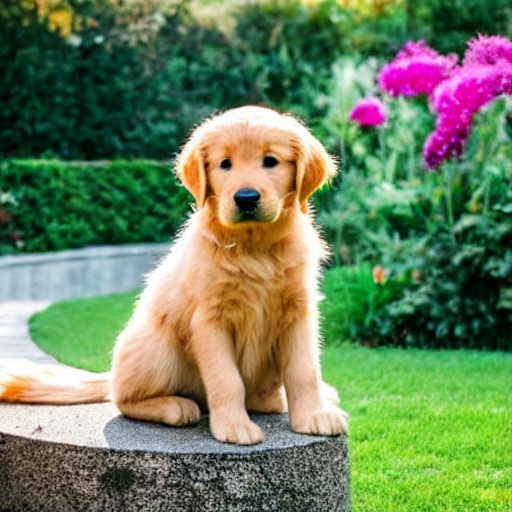

In [27]:
prompt = "A cute golden retriever puppy sitting in a beautiful garden"

image = pipe(prompt).images[0]

image

  0%|          | 0/50 [00:00<?, ?it/s]

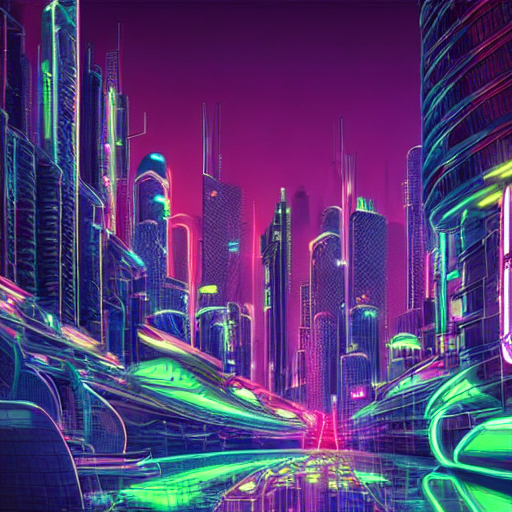

In [28]:
prompt = "A beautiful futuristic city at night, glowing neon lights, cinematic, highly detailed"

image = pipe(prompt).images[0]

image

  0%|          | 0/30 [00:00<?, ?it/s]

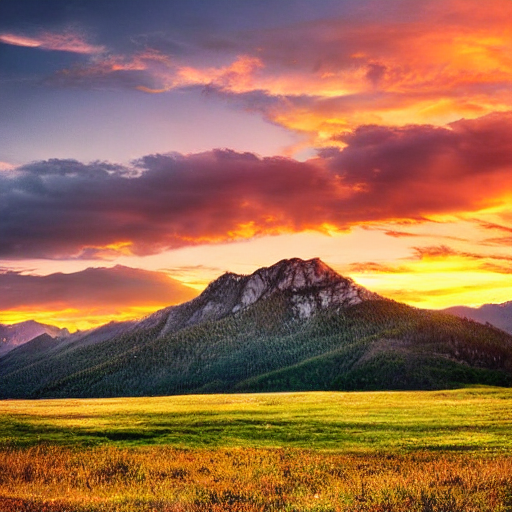

In [29]:
prompt = "A beautiful sunset over the mountains, realistic photography"

image = pipe(
    prompt,
    num_inference_steps=30
).images[0]

image

  0%|          | 0/30 [00:00<?, ?it/s]

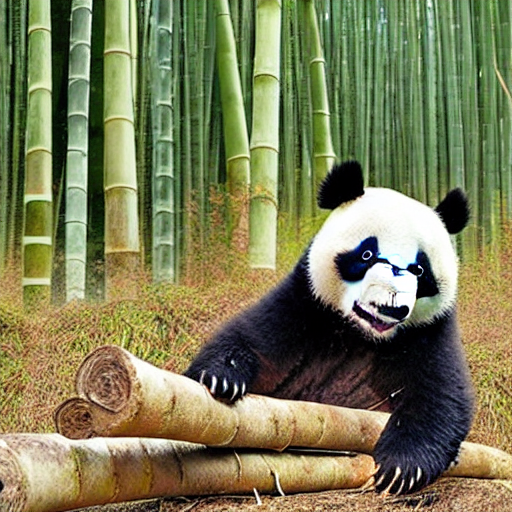

In [30]:
prompt = "A cute panda sitting in a bamboo forest"

image = pipe(
    prompt,
    num_inference_steps=30,
    guidance_scale=7.5
).images[0]

image

  0%|          | 0/30 [00:00<?, ?it/s]

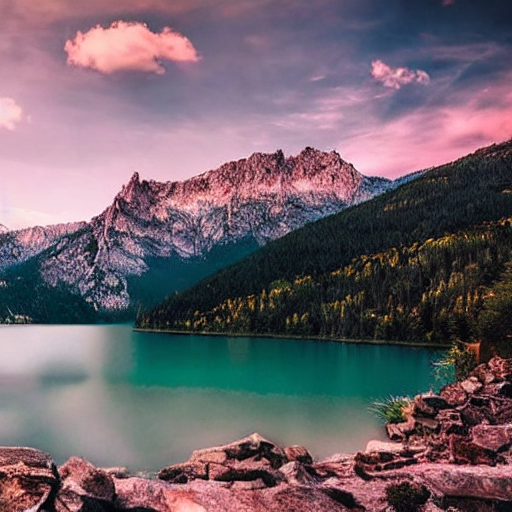

In [31]:
prompt = "A beautiful lake surrounded by mountains, realistic photography"

image = pipe(
    prompt,
    num_inference_steps=30,
    guidance_scale=7.5,
    width=512,
    height=512
).images[0]

image

  0%|          | 0/30 [00:00<?, ?it/s]

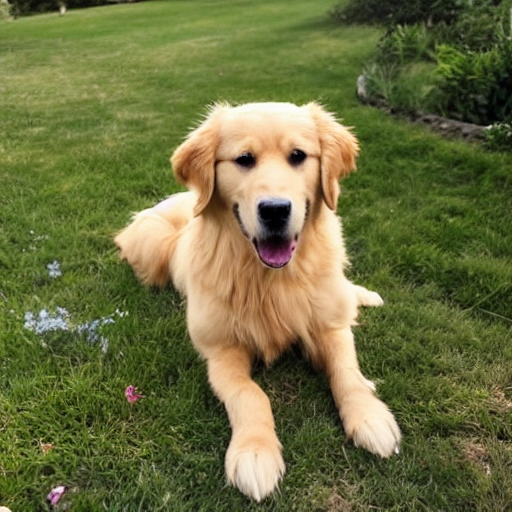

In [32]:
prompt = "A cute golden retriever sitting in a garden"

generator = torch.Generator("cuda").manual_seed(42)

image = pipe(
    prompt,
    num_inference_steps=30,
    guidance_scale=7.5,
    generator=generator
).images[0]

image

In [33]:
!pip install -q streamlit

In [34]:
%%writefile app.py

import streamlit as st
import torch
from diffusers import StableDiffusionPipeline

# Page configuration
st.set_page_config(
    page_title="Generative Image App",
    page_icon="🎨"
)

st.title("🎨 Generative Image Application")
st.write("Generate AI images using Stable Diffusion")

# Load model
@st.cache_resource
def load_model():
    model_id = "runwayml/stable-diffusion-v1-5"

    pipe = StableDiffusionPipeline.from_pretrained(
        model_id,
        torch_dtype=torch.float16
    )

    pipe = pipe.to("cuda")

    return pipe

pipe = load_model()

# User prompt
prompt = st.text_area(
    "Enter your image prompt:",
    "A cute golden retriever puppy sitting in a beautiful garden"
)

# Parameters
steps = st.slider(
    "Inference Steps",
    min_value=10,
    max_value=50,
    value=30
)

guidance = st.slider(
    "Guidance Scale",
    min_value=1.0,
    max_value=15.0,
    value=7.5
)

width = st.selectbox(
    "Image Width",
    [512, 768]
)

height = st.selectbox(
    "Image Height",
    [512, 768]
)

# Generate button
if st.button("🎨 Generate Image"):

    with st.spinner("Generating image..."):

        image = pipe(
            prompt,
            num_inference_steps=steps,
            guidance_scale=guidance,
            width=width,
            height=height
        ).images[0]

    st.image(
        image,
        caption="Generated Image",
        use_container_width=True
    )

    st.success("Image generated successfully! 🎉")

Overwriting app.py


In [35]:
!pip install -q pyngrok

In [36]:
!streamlit run app.py &> /content/streamlit.log &

In [37]:
!ngrok config add-authtoken 3KG6HlvUKAvst6uomP9icpgBKPI_5ysdw1z57XTkvjBse6i94

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [38]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)

print("Your app URL:")
print(public_url)

Your app URL:
NgrokTunnel: "https://carnivore-exponent-rotunda.ngrok-free.dev" -> "http://localhost:8501"


In [39]:
%%writefile app.py

import streamlit as st
import torch
from diffusers import StableDiffusionPipeline
from io import BytesIO

st.set_page_config(
    page_title="Generative Image App",
    page_icon="🎨"
)

st.title("🎨 Generative Image Application")
st.write("Generate AI images using Stable Diffusion")

@st.cache_resource
def load_model():

    model_id = "runwayml/stable-diffusion-v1-5"

    pipe = StableDiffusionPipeline.from_pretrained(
        model_id,
        torch_dtype=torch.float16
    )

    pipe = pipe.to("cuda")

    return pipe

pipe = load_model()

prompt = st.text_area(
    "Enter your image prompt:",
    "A cute golden retriever puppy sitting in a beautiful garden"
)

steps = st.slider(
    "Inference Steps",
    10,
    50,
    30
)

guidance = st.slider(
    "Guidance Scale",
    1.0,
    15.0,
    7.5
)

width = st.selectbox(
    "Image Width",
    [512, 768]
)

height = st.selectbox(
    "Image Height",
    [512, 768]
)

if st.button("🎨 Generate Image"):

    with st.spinner("Generating image..."):

        image = pipe(
            prompt,
            num_inference_steps=steps,
            guidance_scale=guidance,
            width=width,
            height=height
        ).images[0]

    st.image(
        image,
        caption="Generated Image",
        use_container_width=True
    )

    # Convert image to bytes
    image_bytes = BytesIO()
    image.save(image_bytes, format="PNG")

    st.download_button(
        label="💾 Download Image",
        data=image_bytes.getvalue(),
        file_name="generated_image.png",
        mime="image/png"
    )

    st.success("Image generated successfully! 🎉")

Overwriting app.py


In [40]:
%%writefile app.py

import streamlit as st
import torch
from diffusers import StableDiffusionPipeline
from io import BytesIO

st.set_page_config(
    page_title="Generative Image App",
    page_icon="🎨"
)

st.title("🎨 Generative Image Application")
st.write("Generate AI images using Stable Diffusion")

@st.cache_resource
def load_model():

    model_id = "runwayml/stable-diffusion-v1-5"

    pipe = StableDiffusionPipeline.from_pretrained(
        model_id,
        torch_dtype=torch.float16
    )

    pipe = pipe.to("cuda")

    return pipe

pipe = load_model()

# Prompt
prompt = st.text_area(
    "Enter your image prompt:",
    "A cute golden retriever puppy sitting in a beautiful garden"
)

# Parameters
steps = st.slider(
    "Inference Steps",
    min_value=10,
    max_value=50,
    value=30
)

guidance = st.slider(
    "Guidance Scale",
    min_value=1.0,
    max_value=15.0,
    value=7.5
)

width = st.selectbox(
    "Image Width",
    [512, 768]
)

height = st.selectbox(
    "Image Height",
    [512, 768]
)

# Seed
seed = st.number_input(
    "Seed",
    min_value=0,
    max_value=999999,
    value=42,
    step=1
)

# Generate image
if st.button("🎨 Generate Image"):

    generator = torch.Generator("cuda").manual_seed(seed)

    with st.spinner("Generating image..."):

        image = pipe(
            prompt,
            num_inference_steps=steps,
            guidance_scale=guidance,
            width=width,
            height=height,
            generator=generator
        ).images[0]

    st.image(
        image,
        caption=f"Generated Image | Seed: {seed}",
        use_container_width=True
    )

    # Prepare image for download
    image_bytes = BytesIO()
    image.save(image_bytes, format="PNG")

    st.download_button(
        label="💾 Download Image",
        data=image_bytes.getvalue(),
        file_name="generated_image.png",
        mime="image/png"
    )

    st.success("Image generated successfully! 🎉")

Overwriting app.py


In [41]:
%%writefile app.py

import streamlit as st
import torch
from diffusers import StableDiffusionPipeline
from io import BytesIO

st.set_page_config(
    page_title="Generative Image App",
    page_icon="🎨"
)

st.title("🎨 Generative Image Application")
st.write("Generate AI images using Stable Diffusion")

@st.cache_resource
def load_model():

    model_id = "runwayml/stable-diffusion-v1-5"

    pipe = StableDiffusionPipeline.from_pretrained(
        model_id,
        torch_dtype=torch.float16
    )

    pipe = pipe.to("cuda")

    return pipe

pipe = load_model()

# Prompt
prompt = st.text_area(
    "Enter your image prompt:",
    "A cute golden retriever puppy sitting in a beautiful garden"
)

# Parameters
steps = st.slider(
    "Inference Steps",
    min_value=10,
    max_value=50,
    value=30
)

guidance = st.slider(
    "Guidance Scale",
    min_value=1.0,
    max_value=15.0,
    value=7.5
)

width = st.selectbox(
    "Image Width",
    [512, 768]
)

height = st.selectbox(
    "Image Height",
    [512, 768]
)

# Seed
seed = st.number_input(
    "Seed",
    min_value=0,
    max_value=999999,
    value=42,
    step=1
)

# Generate image
if st.button("🎨 Generate Image"):

    generator = torch.Generator("cuda").manual_seed(seed)

    with st.spinner("Generating image..."):

        image = pipe(
            prompt,
            num_inference_steps=steps,
            guidance_scale=guidance,
            width=width,
            height=height,
            generator=generator
        ).images[0]

    st.image(
        image,
        caption=f"Generated Image | Seed: {seed}",
        use_container_width=True
    )

    # Prepare image for download
    image_bytes = BytesIO()
    image.save(image_bytes, format="PNG")

    st.download_button(
        label="💾 Download Image",
        data=image_bytes.getvalue(),
        file_name="generated_image.png",
        mime="image/png"
    )

    st.success("Image generated successfully! 🎉")

Overwriting app.py


In [42]:
%%writefile app.py

import streamlit as st
import torch
from diffusers import StableDiffusionPipeline
from io import BytesIO

# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Generative Image App",
    page_icon="🎨",
    layout="wide"
)

# --------------------------------------------------
# TITLE
# --------------------------------------------------

st.title("🎨 Generative Image Application")
st.subheader("Text-to-Image Generation using Stable Diffusion")

st.write(
    "Enter a text description and let Artificial Intelligence "
    "generate a unique image for you."
)

# --------------------------------------------------
# LOAD MODEL
# --------------------------------------------------

@st.cache_resource
def load_model():

    model_id = "runwayml/stable-diffusion-v1-5"

    pipe = StableDiffusionPipeline.from_pretrained(
        model_id,
        torch_dtype=torch.float16
    )

    pipe = pipe.to("cuda")

    return pipe


pipe = load_model()

# --------------------------------------------------
# SIDEBAR
# --------------------------------------------------

st.sidebar.header("⚙️ Generation Settings")

steps = st.sidebar.slider(
    "Inference Steps",
    min_value=10,
    max_value=50,
    value=30
)

guidance = st.sidebar.slider(
    "Guidance Scale",
    min_value=1.0,
    max_value=15.0,
    value=7.5
)

width = st.sidebar.selectbox(
    "Image Width",
    [512, 768]
)

height = st.sidebar.selectbox(
    "Image Height",
    [512, 768]
)

seed = st.sidebar.number_input(
    "Seed",
    min_value=0,
    max_value=999999,
    value=42,
    step=1
)

# --------------------------------------------------
# PROMPTS
# --------------------------------------------------

st.markdown("### 📝 Enter Your Prompt")

prompt = st.text_area(
    "Positive Prompt",
    "A cute golden retriever puppy sitting in a beautiful garden, realistic photography, highly detailed",
    height=100
)

negative_prompt = st.text_area(
    "Negative Prompt",
    "blurry, low quality, distorted, deformed, extra limbs, extra fingers",
    height=80
)

# --------------------------------------------------
# GENERATE BUTTON
# --------------------------------------------------

generate = st.button(
    "🎨 Generate Image",
    use_container_width=True
)

# --------------------------------------------------
# IMAGE GENERATION
# --------------------------------------------------

if generate:

    generator = torch.Generator("cuda").manual_seed(seed)

    with st.spinner("🤖 AI is generating your image..."):

        image = pipe(
            prompt=prompt,
            negative_prompt=negative_prompt,
            num_inference_steps=steps,
            guidance_scale=guidance,
            width=width,
            height=height,
            generator=generator
        ).images[0]

    # --------------------------------------------------
    # DISPLAY IMAGE
    # --------------------------------------------------

    st.markdown("### 🖼️ Generated Image")

    st.image(
        image,
        caption=f"Generated using Stable Diffusion | Seed: {seed}",
        use_container_width=True
    )

    # --------------------------------------------------
    # DOWNLOAD
    # --------------------------------------------------

    image_bytes = BytesIO()

    image.save(
        image_bytes,
        format="PNG"
    )

    st.download_button(
        label="💾 Download Image",
        data=image_bytes.getvalue(),
        file_name="stable_diffusion_image.png",
        mime="image/png",
        use_container_width=True
    )

    st.success("🎉 Image generated successfully!")

# --------------------------------------------------
# INFORMATION
# --------------------------------------------------

st.markdown("---")

st.markdown(
    """
    ### 📌 About This Application

    This application uses Stable Diffusion, a latent diffusion
    model, to generate images from natural language text prompts.

    **Technology Stack:**
    - Python
    - PyTorch
    - Hugging Face Diffusers
    - Stable Diffusion
    - Streamlit
    - CUDA GPU
    """
)

Overwriting app.py
